In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import seaborn as sns


# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


# Models
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix


# Make sure nltk resources are downloaded
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [5]:
# 1. Load dataset
# ----------------------
# Example: dataset should have columns ["review", "sentiment"]
# sentiment = positive / negative
df = pd.read_csv("I.csv")
print(df.head())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [15]:
# 2. Text cleaning
# ----------------------
stop_words = set(stopwords.words('english'))


def clean_text(text):
  text = re.sub(r'[^a-zA-Z ]', '', text)
  text = text.lower().split()
  text = [w for w in text if w not in stop_words and w != "br"]
  return " ".join(text)


df["cleaned"] = df["review"].astype(str).apply(clean_text)

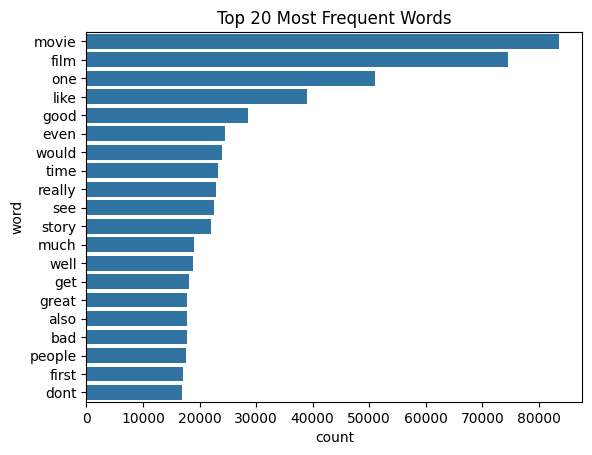

In [16]:
# 3. Word Frequency Analysis
# ----------------------
all_words = " ".join(df["cleaned"]).split()
word_freq = Counter(all_words).most_common(20)


freq_df = pd.DataFrame(word_freq, columns=["word", "count"])
sns.barplot(x="count", y="word", data=freq_df)
plt.title("Top 20 Most Frequent Words")
plt.show()

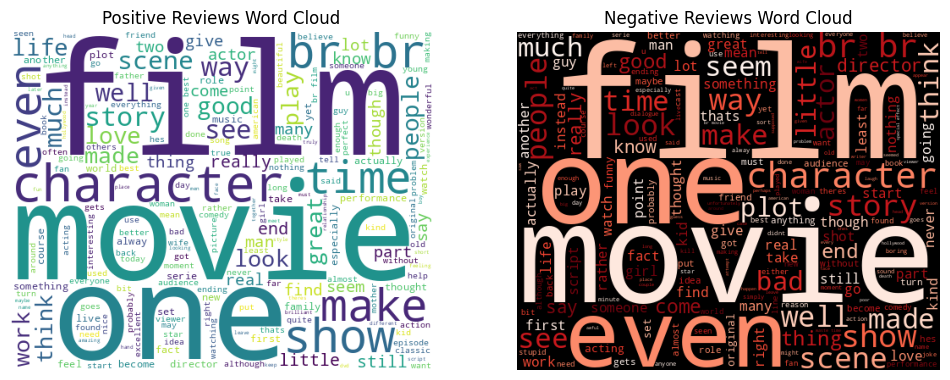

In [ ]:
# 4. Word Clouds by Sentiment
# ----------------------
pos_text = " ".join(df[df["sentiment"]=="positive"]["cleaned"])
neg_text = " ".join(df[df["sentiment"]=="negative"]["cleaned"])


plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
wc = WordCloud(width=500, height=400, background_color="white").generate(pos_text)
plt.imshow(wc)
plt.axis("off")
plt.title("Positive Reviews Word Cloud")


plt.subplot(1,2,2)
wc = WordCloud(width=500, height=400, background_color="black", colormap="Reds").generate(neg_text)
plt.imshow(wc)
plt.axis("off")
plt.title("Negative Reviews Word Cloud")


plt.show()

In [11]:
# 5. Vectorization
# ----------------------
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df["cleaned"])
y = df["sentiment"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
# 6. Train Models
# ----------------------
# Naive Bayes
nb = MultinomialNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)
print("Naive Bayes Classification Report:\n", classification_report(y_test, nb_pred))


# SVM
svm = LinearSVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
print("SVM Classification Report:\n", classification_report(y_test, svm_pred))

Naive Bayes Classification Report:
               precision    recall  f1-score   support

    negative       0.85      0.85      0.85      4961
    positive       0.85      0.85      0.85      5039

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000

SVM Classification Report:
               precision    recall  f1-score   support

    negative       0.89      0.87      0.88      4961
    positive       0.87      0.89      0.88      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



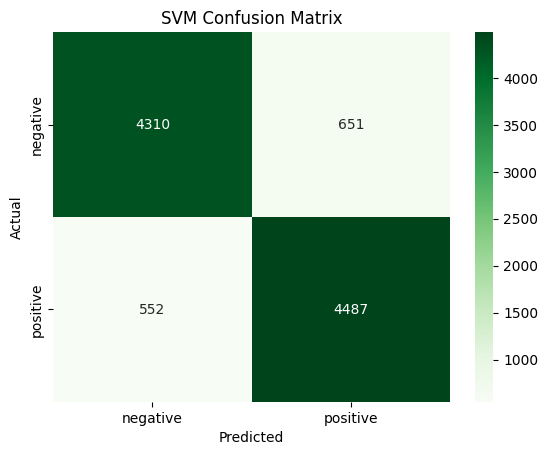

In [ ]:
# Confusion matrix for SVM
svm_cm = confusion_matrix(y_test, svm_pred)
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Greens', xticklabels=svm.classes_, yticklabels=svm.classes_)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()